In [129]:
import numpy as np
import matplotlib.pyplot as plt
import yfinance

plt.style.use('ggplot')

In [130]:
def simulate_vasicek(r0, kappa, theta, sigma, dt, N, steps):
    r = np.zeros((steps, N))
    r[0,:] = r0

    c1 = np.exp(-kappa*dt)
    c2 = theta*(1-np.exp(-kappa*dt))
    c3 = np.sqrt((sigma**2*(1-np.exp(-2*kappa*dt)))/(2*kappa))
    
    for n in range(1, steps):
        Z = np.random.standard_normal(N)
        r[n,:] = r[n-1,:]*c1 + np.ones(N)*c2 + Z*c3

    return r

In [131]:
dt = 1/252
kappa = 4
theta = 3
sigma = 0.5
Nsimul = 6

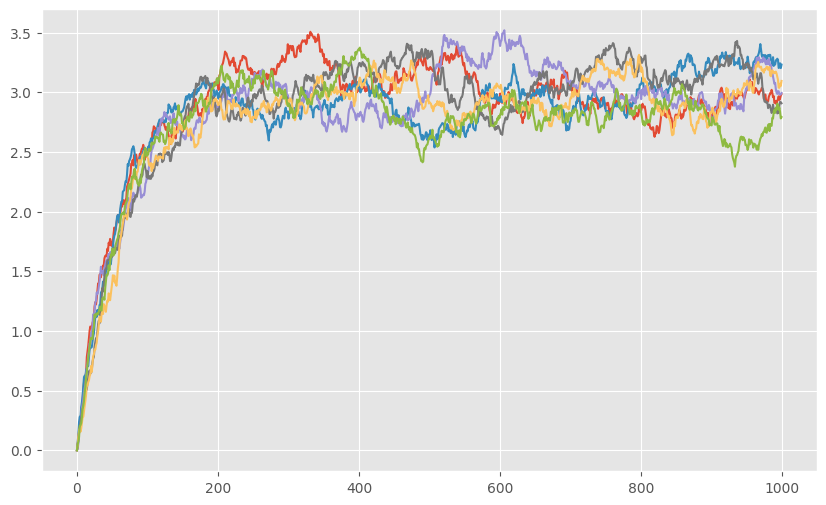

In [132]:
r0 = np.zeros(Nsimul)
rates = simulate_vasicek(r0, kappa, theta, sigma, dt, Nsimul, 1000)

plt.figure(figsize=(10, 6))
plt.plot(rates)
plt.show()

In [133]:
def pdf(r, r0, kappa, theta, sigma, dt):
    mean = r0 * np.exp(-kappa * dt) + theta * (
        -np.expm1(-kappa * dt)
    )
    variance = sigma**2 * (-np.expm1(-2 * kappa * dt)) / (2 * kappa)

    return np.exp(-0.5 * (r - mean)**2 / variance) / np.sqrt(
        2 * np.pi * variance
    )

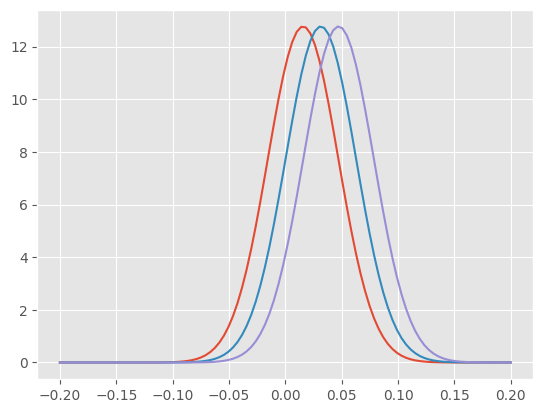

In [145]:
r = np.linspace(-0.2, 0.2, 100)

params = [1, 2, 3] # theta
for param in params:
    prob = pdf(r, 0, kappa, param, sigma, dt)
    plt.plot(r, prob)

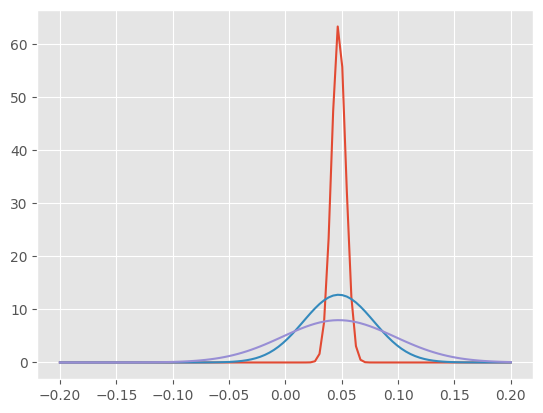

In [151]:
r = np.linspace(-0.2, 0.2, 100)

params = [0.1, 0.5, 0.8] # sigma
for param in params:
    prob = pdf(r, 0, kappa, theta, param, dt)
    plt.plot(r, prob)

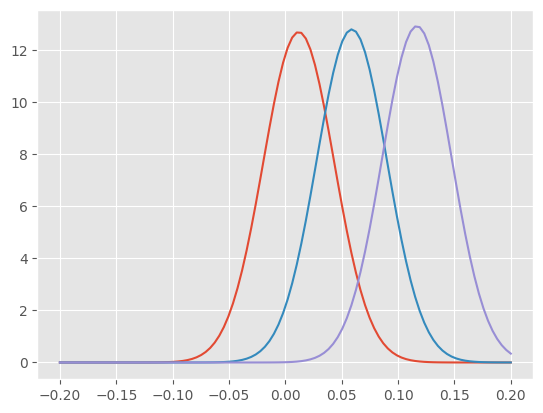

In [154]:
r = np.linspace(-0.2, 0.2, 100)

params = [1, 5, 10] # kappa
for param in params:
    prob = pdf(r, 0, param, theta, sigma, dt)
    plt.plot(r, prob)

## Model Calibration

In [33]:
# Get market values
Trates_series = yfinance.download("^FVX", start="2021-01-01", end="2026-01-01")["Close"]

[*********************100%***********************]  1 of 1 completed


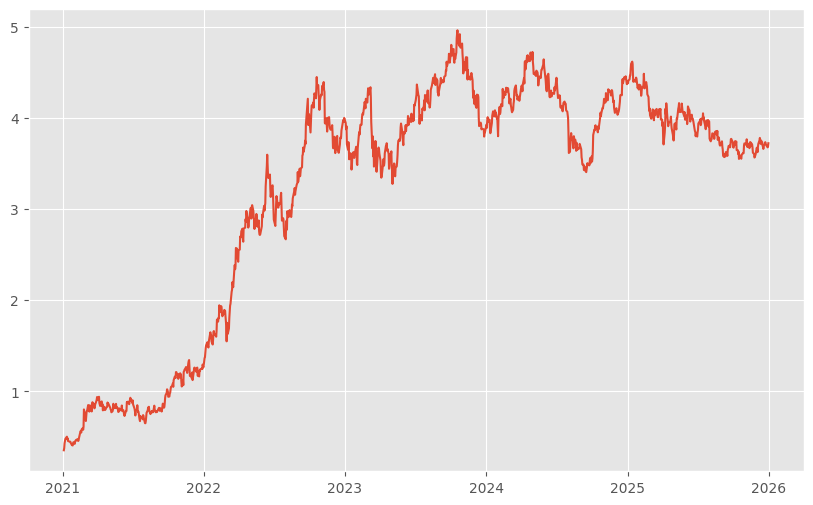

In [34]:
plt.figure(figsize=(10, 6))
plt.plot(Trates_series)
plt.show()

In [73]:
# Calibrate the model using OLS

Trates = Trates_series.to_numpy()
X = np.column_stack([np.ones(len(Trates) - 1), Trates[:-1]])
a, b = np.linalg.lstsq(X, Trates[1:])[0]
residuals = Trates[1:] - (a + b * Trates[:-1])

kappa_cal = - np.log(b) / dt
theta_cal = a / (1-b)
sigma_cal = np.sqrt((2*kappa_cal*np.var(residuals))/(1-b**2))

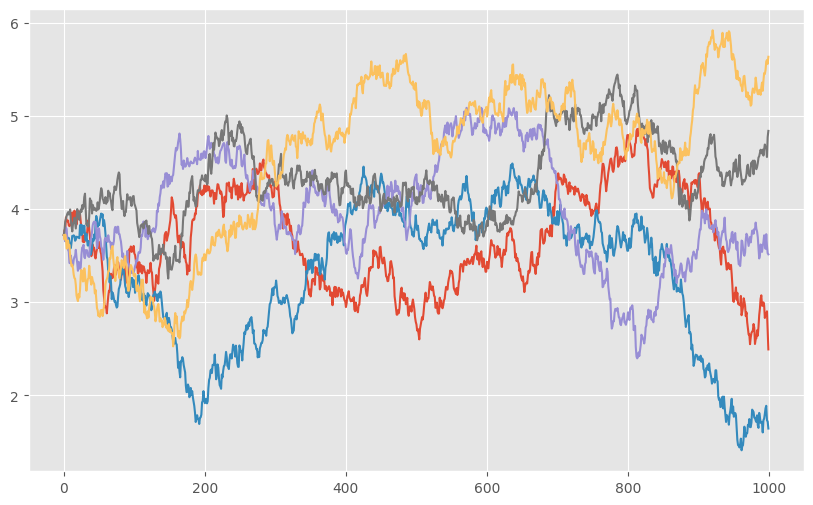

In [127]:
r0 = Trates[-1]
T = 1000

rates = simulate_vasicek(r0, kappa_cal, theta_cal, sigma_cal, dt, 5, T)

plt.figure(figsize=(10, 6))
plt.plot(rates)
plt.show()

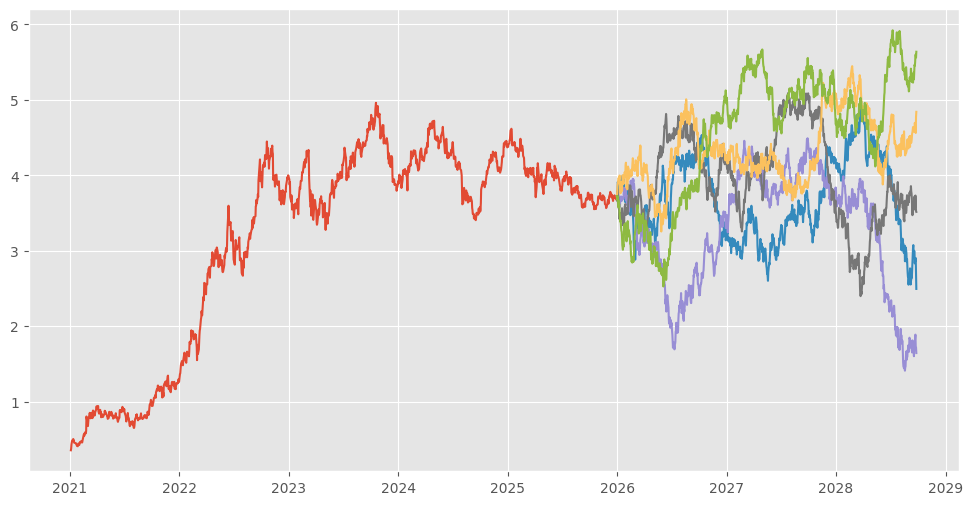

In [128]:
import pandas as pd

dates = pd.date_range(start=Trates_series.index[-1], periods=T, freq="D")

plt.figure(figsize=(12, 6))
plt.plot(Trates_series)
plt.plot(dates, rates)
plt.show()